# Paper tables and figures

Builds the paper's results tables and figures from the finished runs. Nothing is trained or scored here: every number is read from an earlier notebook's output.

**Tables** (each written as CSV, LaTeX with booktabs, and Markdown):
1. `t1_test`: the single test. Per backbone and finalist (no entangler): val, FF++ test with its 95% interval and per manipulation, Celeb-DF with its interval; the linear probe on all features as the last row.
2. `t2_paired`: each finalist against random search and against PLS 8 on FF++ test and Celeb-DF (seed-averaged scores, paired bootstrap); a star marks an interval that excludes 0.
3. `t3_entangler`: CZ ring minus no entangler, paired by seed, on val, FF++ test and Celeb-DF.
4. `t4_c1`: claim C1, input gap against circuit gap per backbone.
5. `t5_context`: the context table: twin, logistic regression and the 4-unit MLP on the same 8 inputs, and the probe (val and held-out).
6. `t6_search_stats`: the search methods as real circuits on val (Kruskal-Wallis, Holm-corrected Mann-Whitney against random search, A12).
7. `t7_c3`: claim C3, the best searched finalist and PLS 8 as a share of the probe on val, FF++ test and Celeb-DF.

**Figures** (PDF and PNG):
1. `f1_test_auc`: FF++ test and Celeb-DF AUC per finalist, with and without the CZ ring, and the probe.
2. `f2_c1_gaps`: input gap against circuit gaps.
3. `f3_per_manipulation`: FF++ test AUC per manipulation for the best searched finalist, PLS 8, first 8 PCA and the probe.
4. `f4_probe_share`: share of the probe (C3).
5. `f5_context`: logistic regression and MLP minus the twin on each 8-input set.

The figures that already exist (`anytime.png` in `search_analysis`, `circuit_val.png` and `twin_vs_circuit.png` in `final_circuits`) are not redrawn.

**Inputs (Add Input):** the outputs of `faridaali202301940/single-test` (folder `single_test/`), `faridaali202301940/context-table` (folder `context_table/`) and `malakkhaled202300369/final-circuits` (folder `final_circuits/`).

**Settings:** Accelerator None (CPU). No installs needed.

## 1. Settings

In [1]:
out_dir = "/kaggle/working/paper_figures"
backbones = ["l14", "b16", "effb4"]
titles = {"l14": "CLIP ViT-L/14", "b16": "CLIP ViT-B/16", "effb4": "EfficientNet-B4"}
finalist_order = ["memetic GA", "GA", "PSO", "random", "greedy", "PLS 8", "first 8 PCA"]
searched = ["memetic GA", "GA", "PSO", "random"]
manipulations = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]
# the search methods keep final_circuits' colors; baselines are greys and a purple
colors = {"GA": "#257de0", "memetic GA": "#f47230", "PSO": "#00b894", "DE": "#f2a600", "GWO": "#ee7fac",
          "random": "#8a8a8a", "greedy": "#2d3436", "PLS 8": "#6c5ce7", "first 8 PCA": "#b2bec3", "probe": "#d63031",
          "best searched": "#0f766e"}
dpi = 300

## 2. Imports and inputs

In [2]:
import os
import glob
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

os.makedirs(f"{out_dir}/tables", exist_ok=True)
os.makedirs(f"{out_dir}/figures", exist_ok=True)
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#999999", "axes.labelcolor": "#333333", "xtick.color": "#555555",
                     "ytick.color": "#555555", "pdf.fonttype": 42, "ps.fonttype": 42, "font.family": "DejaVu Sans"})


def find_one(filename, folder):
    hits = [p for p in sorted(glob.glob("/kaggle/input/**/" + filename, recursive=True))
            if os.path.basename(os.path.dirname(p)) == folder]
    assert len(hits) == 1, (filename, folder, hits)
    return hits[0]


st = os.path.dirname(find_one("test_summary.csv", "single_test"))
summary = pd.read_csv(f"{st}/test_summary.csv")
paired = pd.read_csv(f"{st}/paired_differences.csv")
ring_test = pd.read_csv(f"{st}/entangler_test.csv")
probe = pd.read_csv(f"{st}/probe.csv").set_index("backbone")
context = pd.read_csv(find_one("context_table.csv", "context_table"))
fc = os.path.dirname(find_one("stage_a_stats.csv", "final_circuits"))
stage_stats = pd.read_csv(f"{fc}/stage_a_stats.csv")
twin_circuit = pd.read_csv(f"{fc}/twin_vs_circuit.csv").set_index("backbone")
ring_val = pd.read_csv(f"{fc}/entangler_effect.csv")
assert set(summary["backbone"]) == set(backbones), set(summary["backbone"])
print("single test:", len(summary), "rows | paired:", len(paired), "| context:", len(context), "| stats:", len(stage_stats))

single test: 42 rows | paired: 42 | context: 105 | stats: 15


## 3. Writers

A table is a DataFrame of display strings. `save_table` writes it as CSV, a booktabs LaTeX table (with `\midrule` between backbones) and Markdown, and prints it.

In [3]:
def ci(v, low, high, d=3):
    return f"{v:.{d}f} [{low:.{d}f}, {high:.{d}f}]"


def signed(v, low=None, high=None, d=3):
    s = f"{v:+.{d}f}"
    if low is not None:
        s += f" [{low:+.{d}f}, {high:+.{d}f}]"
        if low > 0 or high < 0:
            s += "*"
    return s


def latex_escape(s):
    return str(s).replace("&", r"\&").replace("%", r"\%").replace("_", r"\_").replace("#", r"\#")


def save_table(df, name, caption, group_col="Backbone"):
    df.to_csv(f"{out_dir}/tables/{name}.csv", index=False)
    cols = list(df.columns)
    lines = [r"\begin{table}[t]", r"\centering", r"\small", rf"\caption{{{latex_escape(caption)}}}",
             rf"\label{{tab:{name}}}", r"\begin{tabular}{" + "l" * 2 + "r" * (len(cols) - 2) + "}", r"\toprule",
             " & ".join(latex_escape(c) for c in cols) + r" \\", r"\midrule"]
    previous = None
    for _, row in df.iterrows():
        if group_col in df.columns and previous is not None and row[group_col] != previous:
            lines.append(r"\midrule")
        previous = row[group_col] if group_col in df.columns else None
        lines.append(" & ".join(latex_escape(v) for v in row.values) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    with open(f"{out_dir}/tables/{name}.tex", "w") as f:
        f.write("\n".join(lines) + "\n")
    md = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    md += ["| " + " | ".join(str(v) for v in row.values) + " |" for _, row in df.iterrows()]
    with open(f"{out_dir}/tables/{name}.md", "w") as f:
        f.write(f"**{caption}**\n\n" + "\n".join(md) + "\n")
    print(f"\n{name}: {caption}")
    print(df.to_string(index=False))


def save_figure(fig, name):
    fig.savefig(f"{out_dir}/figures/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"{out_dir}/figures/{name}.png", dpi=dpi, bbox_inches="tight")
    plt.show()

## 4. Table 1: the single test

In [4]:
none = summary[summary["entangler"] == "none"].set_index(["backbone", "finalist"])
short = {"Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS", "NeuralTextures": "NT"}
rows = []
for b in backbones:
    for f in finalist_order:
        r = none.loc[(b, f)]
        rows.append({"Backbone": titles[b], "Input set": f, "Val": f"{r['val']:.3f}",
                     "FF++ test": ci(r["ffpp_test auc"], r["ffpp_test low"], r["ffpp_test high"]),
                     **{short[m]: f"{r['ffpp_test ' + m]:.3f}" for m in manipulations},
                     "Celeb-DF": ci(r["celebdf_test auc"], r["celebdf_test low"], r["celebdf_test high"])})
    p = probe.loc[b]
    rows.append({"Backbone": titles[b], "Input set": "probe, all features", "Val": f"{p['val auc']:.3f}",
                 "FF++ test": ci(p["ffpp_test auc"], p["ffpp_test low"], p["ffpp_test high"]),
                 **{short[m]: f"{p['ffpp_test ' + m]:.3f}" for m in manipulations},
                 "Celeb-DF": ci(p["celebdf_test auc"], p["celebdf_test low"], p["celebdf_test high"])})
t1 = pd.DataFrame(rows)
save_table(t1, "t1_test", "Single test: video AUC of the final circuits (8 qubits, no entangler, mean over 5 seeds, "
           "95% bootstrap interval) on FF++ test, per FF++ manipulation, and on Celeb-DF, with the linear probe on all features.")


t1_test: Single test: video AUC of the final circuits (8 qubits, no entangler, mean over 5 seeds, 95% bootstrap interval) on FF++ test, per FF++ manipulation, and on Celeb-DF, with the linear probe on all features.
       Backbone           Input set   Val            FF++ test    DF   F2F    FS    NT             Celeb-DF
  CLIP ViT-L/14          memetic GA 0.893 0.894 [0.867, 0.919] 0.972 0.888 0.955 0.762 0.793 [0.751, 0.833]
  CLIP ViT-L/14                  GA 0.890 0.893 [0.866, 0.918] 0.973 0.882 0.956 0.761 0.776 [0.733, 0.817]
  CLIP ViT-L/14                 PSO 0.888 0.888 [0.861, 0.912] 0.973 0.880 0.956 0.742 0.753 [0.708, 0.795]
  CLIP ViT-L/14              random 0.864 0.868 [0.839, 0.895] 0.972 0.853 0.947 0.699 0.769 [0.725, 0.812]
  CLIP ViT-L/14              greedy 0.893 0.894 [0.867, 0.919] 0.972 0.888 0.955 0.762 0.793 [0.751, 0.833]
  CLIP ViT-L/14               PLS 8 0.888 0.894 [0.867, 0.918] 0.971 0.886 0.953 0.764 0.791 [0.749, 0.830]
  CLIP ViT-L/14         firs

## 5. Table 2: paired differences

In [5]:
rows = []
for b in backbones:
    for f in finalist_order:
        r = {"Backbone": titles[b], "Input set": f}
        for split, label in [("ffpp_test", "FF++ test"), ("celebdf_test", "Celeb-DF")]:
            x = paired[(paired["backbone"] == b) & (paired["split"] == split) & (paired["finalist"] == f)].iloc[0]
            r[f"{label} AUC"] = f"{x['auc (seed mean scores)']:.3f}"
            r[f"{label} vs random"] = "-" if f == "random" else signed(x["minus random"], x["minus random low"], x["minus random high"])
            r[f"{label} vs PLS 8"] = "-" if f == "PLS 8" else signed(x["minus PLS 8"], x["minus PLS 8 low"], x["minus PLS 8 high"])
        rows.append(r)
save_table(pd.DataFrame(rows), "t2_paired", "AUC difference against random search and against PLS 8 (seed-averaged "
           "scores, no entangler, paired bootstrap over videos, 95% interval; * the interval excludes 0).")


t2_paired: AUC difference against random search and against PLS 8 (seed-averaged scores, no entangler, paired bootstrap over videos, 95% interval; * the interval excludes 0).
       Backbone   Input set FF++ test AUC      FF++ test vs random       FF++ test vs PLS 8 Celeb-DF AUC       Celeb-DF vs random        Celeb-DF vs PLS 8
  CLIP ViT-L/14  memetic GA         0.894 +0.026 [+0.010, +0.042]*  +0.001 [-0.007, +0.009]        0.793 +0.025 [+0.002, +0.046]*  +0.003 [-0.008, +0.012]
  CLIP ViT-L/14          GA         0.893 +0.025 [+0.011, +0.040]*  -0.001 [-0.006, +0.004]        0.776  +0.007 [-0.010, +0.022] -0.015 [-0.022, -0.007]*
  CLIP ViT-L/14         PSO         0.888 +0.020 [+0.004, +0.034]*  -0.006 [-0.016, +0.004]        0.753  -0.016 [-0.035, +0.001] -0.038 [-0.051, -0.026]*
  CLIP ViT-L/14      random         0.868                        - -0.026 [-0.040, -0.012]*        0.769                        - -0.022 [-0.038, -0.005]*
  CLIP ViT-L/14      greedy         0.894 +0.026 

## 6. Table 3: the entangler

In [6]:
rows = []
for b in backbones:
    for f in finalist_order:
        v = ring_val[(ring_val["backbone"] == b) & (ring_val["finalist"] == f)].iloc[0]
        r = {"Backbone": titles[b], "Input set": f, "Val": signed(v["CZ ring - none mean"])}
        for split, label in [("ffpp_test", "FF++ test"), ("celebdf_test", "Celeb-DF")]:
            x = ring_test[(ring_test["backbone"] == b) & (ring_test["finalist"] == f) & (ring_test["split"] == split)].iloc[0]
            r[label] = signed(x["ring - none mean"])
            r[label + " seeds helped"] = f"{int(x['seeds where the ring helps'])}/5"
        rows.append(r)
save_table(pd.DataFrame(rows), "t3_entangler", "CZ ring minus no entangler (AUC, mean over 5 seeds paired by seed), "
           "and the number of seeds where the ring helps.")


t3_entangler: CZ ring minus no entangler (AUC, mean over 5 seeds paired by seed), and the number of seeds where the ring helps.
       Backbone   Input set    Val FF++ test FF++ test seeds helped Celeb-DF Celeb-DF seeds helped
  CLIP ViT-L/14  memetic GA -0.000    -0.000                    3/5   -0.000                   1/5
  CLIP ViT-L/14          GA +0.001    +0.001                    5/5   +0.000                   3/5
  CLIP ViT-L/14         PSO +0.001    +0.001                    5/5   +0.003                   4/5
  CLIP ViT-L/14      random +0.000    -0.000                    1/5   -0.001                   2/5
  CLIP ViT-L/14      greedy -0.000    -0.000                    3/5   -0.000                   1/5
  CLIP ViT-L/14       PLS 8 +0.000    +0.000                    3/5   +0.000                   2/5
  CLIP ViT-L/14 first 8 PCA -0.001    +0.002                    4/5   +0.010                   5/5
  CLIP ViT-B/16  memetic GA +0.002    -0.000                    2/5   +0.004   

## 7. Table 4: claim C1

Input gap: the best input set minus the first 8 PCA components (no entangler), on val and FF++ test. Circuit gaps: the largest absolute CZ ring effect over the finalists on FF++ test, and the largest gap between the circuit and its classical twin on val over every stage A genome (from `final_circuits`).

In [7]:
rows, c1 = [], {}
for b in backbones:
    s = none.loc[b]
    best_val = s.loc[finalist_order, "val"].max()
    best_test = s.loc[finalist_order, "ffpp_test auc"].max()
    input_val = best_val - s.loc["first 8 PCA", "val"]
    input_test = best_test - s.loc["first 8 PCA", "ffpp_test auc"]
    ring_gap = ring_test[(ring_test["backbone"] == b) & (ring_test["split"] == "ffpp_test")]["ring - none mean"].abs().max()
    twin_gap = twin_circuit.loc[b, "largest gap"]
    c1[b] = {"input gap": input_test, "CZ ring effect": ring_gap, "circuit vs twin": twin_gap}
    rows.append({"Backbone": titles[b], "Input gap, val": f"{input_val:.3f}", "Input gap, FF++ test": f"{input_test:.3f}",
                 "Largest CZ ring effect, test": f"{ring_gap:.3f}", "Largest circuit-twin gap, val": f"{twin_gap:.3f}",
                 "Twin-circuit Spearman": f"{twin_circuit.loc[b, 'spearman']:.3f}",
                 "Input gap / ring effect": f"{input_test / ring_gap:.0f}x"})
save_table(pd.DataFrame(rows), "t4_c1", "Claim C1: choosing the 8 inputs moves AUC far more than changing the circuit.")


t4_c1: Claim C1: choosing the 8 inputs moves AUC far more than changing the circuit.
       Backbone Input gap, val Input gap, FF++ test Largest CZ ring effect, test Largest circuit-twin gap, val Twin-circuit Spearman Input gap / ring effect
  CLIP ViT-L/14          0.156                0.159                        0.002                         0.014                 0.991                     65x
  CLIP ViT-B/16          0.212                0.220                        0.005                         0.005                 0.995                     46x
EfficientNet-B4          0.188                0.191                        0.007                         0.005                 0.996                     26x


## 8. Table 5: the context table

In [8]:
model_order = ["twin", "logistic regression", "MLP"]
rows = []
for b in backbones:
    c = context[(context["backbone"] == b) & (context["model"] != "linear probe")]
    for row_name in dict.fromkeys(c["row"]):
        g = c[c["row"] == row_name].set_index("model")
        r = {"Backbone": titles[b], "Input set": row_name}
        for m, short in zip(model_order, ["twin", "LR", "MLP"]):
            r[f"{short} val"] = f"{g.loc[m, 'val']:.3f}"
        for m, short in zip(model_order, ["twin", "LR", "MLP"]):
            r[f"{short} held-out"] = f"{g.loc[m, 'held-out mean']:.3f}"
        r["worst held-out (twin)"] = f"{g.loc['twin', 'held-out worst']:.3f}"
        rows.append(r)
    p = context[(context["backbone"] == b) & (context["model"] == "linear probe")].iloc[0]
    rows.append({"Backbone": titles[b], "Input set": f"probe, all {int(p['weights']) - 1} features",
                 "twin val": "-", "LR val": f"{p['val']:.3f}", "MLP val": "-", "twin held-out": "-",
                 "LR held-out": f"{p['held-out mean']:.3f}", "MLP held-out": "-",
                 "worst held-out (twin)": f"{p['held-out worst']:.3f} (probe)"})
save_table(pd.DataFrame(rows), "t5_context", "Context table: the classical twin of the circuit, logistic regression "
           "(LR) and a 4-unit MLP (41 weights) on the same 8 inputs, and the linear probe on all features. Val and "
           "held-out-manipulation video AUC (PLS refit inside each fold).")


t5_context: Context table: the classical twin of the circuit, logistic regression (LR) and a 4-unit MLP (41 weights) on the same 8 inputs, and the linear probe on all features. Val and held-out-manipulation video AUC (PLS refit inside each fold).
       Backbone                Input set twin val LR val MLP val twin held-out LR held-out MLP held-out worst held-out (twin)
  CLIP ViT-L/14              first 8 PCA    0.738  0.739   0.749         0.736       0.738        0.742                 0.474
  CLIP ViT-L/14              strongest 8    0.851  0.855   0.858         0.798       0.800        0.794                 0.556
  CLIP ViT-L/14                    PLS 8    0.888  0.891   0.889         0.813       0.815        0.811                 0.574
  CLIP ViT-L/14                 MI top 8    0.849  0.852   0.848         0.801       0.802        0.800                 0.549
  CLIP ViT-L/14                   greedy    0.894  0.895   0.892         0.813       0.813        0.811                 0.

## 9. Table 6: the search methods as real circuits

In [9]:
rows = []
for b in backbones:
    s = stage_stats[stage_stats["backbone"] == b]
    for _, r in s.iterrows():
        rows.append({"Backbone": titles[b], "Method": r["method"], "Mean diff vs random": signed(r["mean diff vs random"]),
                     "A12 vs random": f"{r['A12 vs random']:.2f}",
                     "p (Holm)": "-" if pd.isna(r["p Holm"]) else f"{r['p Holm']:.4f}",
                     "Kruskal-Wallis": f"H = {r['Kruskal-Wallis H']:.1f}, p = {r['Kruskal-Wallis p']:.1e}"})
save_table(pd.DataFrame(rows), "t6_search_stats", "Search methods as real circuits on val (top genome of each run, "
           "10 runs; DE and GWO 5 runs, descriptive): mean difference from random search, A12, Holm-corrected "
           "Mann-Whitney p, and Kruskal-Wallis across random search, GA, PSO and memetic GA.")


t6_search_stats: Search methods as real circuits on val (top genome of each run, 10 runs; DE and GWO 5 runs, descriptive): mean difference from random search, A12, Holm-corrected Mann-Whitney p, and Kruskal-Wallis across random search, GA, PSO and memetic GA.
       Backbone     Method Mean diff vs random A12 vs random p (Holm)        Kruskal-Wallis
  CLIP ViT-L/14         GA              +0.033          1.00   0.0005 H = 28.0, p = 3.6e-06
  CLIP ViT-L/14        PSO              +0.019          0.89   0.0036 H = 28.0, p = 3.6e-06
  CLIP ViT-L/14 memetic GA              +0.039          1.00   0.0005 H = 28.0, p = 3.6e-06
  CLIP ViT-L/14         DE              -0.001          0.58        - H = 28.0, p = 3.6e-06
  CLIP ViT-L/14        GWO              +0.014          0.84        - H = 28.0, p = 3.6e-06
  CLIP ViT-B/16         GA              +0.035          0.94   0.0030 H = 22.7, p = 4.7e-05
  CLIP ViT-B/16        PSO              +0.015          0.76   0.0539 H = 22.7, p = 4.7e-05
  C

## 10. Table 7: claim C3

The best searched finalist is the searched finalist (random search, GA, PSO, memetic GA) with the highest val AUC, so it is picked without test. Its AUC and PLS 8's are divided by the probe's on val, FF++ test and Celeb-DF.

In [10]:
rows, c3 = [], {}
for b in backbones:
    s = none.loc[b]
    best = s.loc[searched, "val"].idxmax()
    p = probe.loc[b]
    c3[b] = {}
    for name in [best, "PLS 8"]:
        shares = {"val": s.loc[name, "val"] / p["val auc"],
                  "FF++ test": s.loc[name, "ffpp_test auc"] / p["ffpp_test auc"],
                  "Celeb-DF": s.loc[name, "celebdf_test auc"] / p["celebdf_test auc"]}
        c3[b][name if name == "PLS 8" else f"best searched ({name})"] = shares
        rows.append({"Backbone": titles[b], "Input set": name if name == "PLS 8" else f"{name} (best searched)",
                     **{k: f"{v * 100:.1f}%" for k, v in shares.items()}})
save_table(pd.DataFrame(rows), "t7_c3", "Claim C3: AUC of 8 inputs on 8 qubits as a share of the linear probe on all features.")


t7_c3: Claim C3: AUC of 8 inputs on 8 qubits as a share of the linear probe on all features.
       Backbone                  Input set   val FF++ test Celeb-DF
  CLIP ViT-L/14 memetic GA (best searched) 98.7%     98.2%   103.9%
  CLIP ViT-L/14                      PLS 8 98.1%     98.1%   103.6%
  CLIP ViT-B/16         GA (best searched) 96.0%     93.9%    91.7%
  CLIP ViT-B/16                      PLS 8 95.9%     96.0%    95.2%
EfficientNet-B4 memetic GA (best searched) 93.7%     95.5%    99.4%
EfficientNet-B4                      PLS 8 91.0%     94.5%   103.9%


## 11. Figure 1: test AUC per finalist

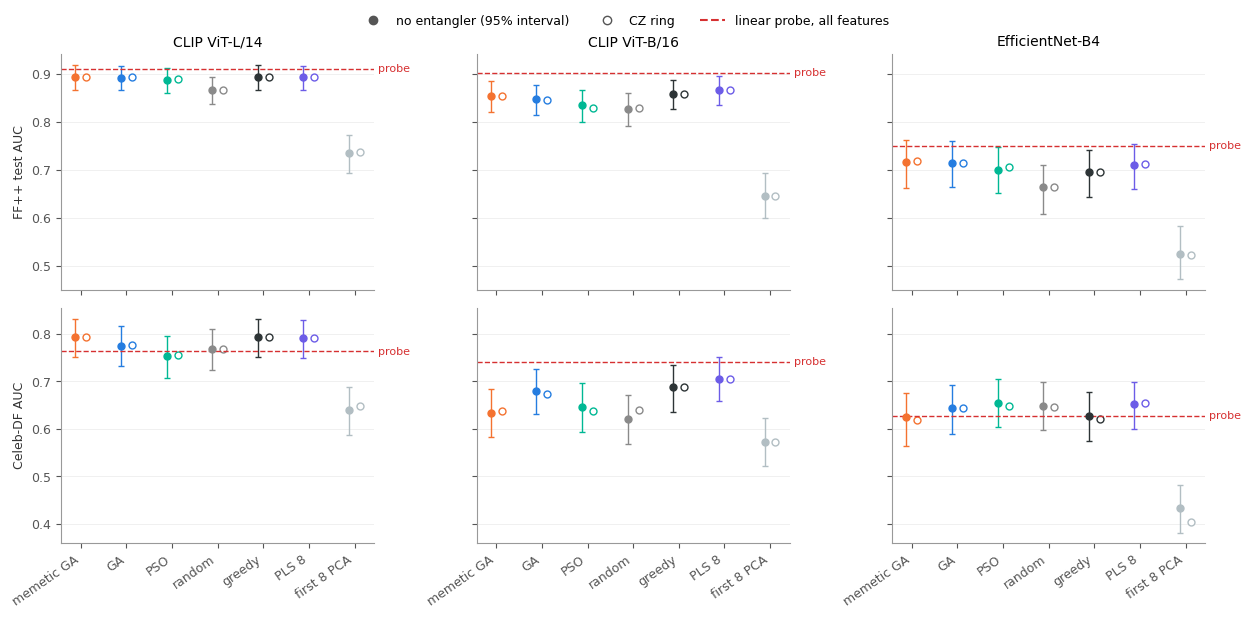

In [11]:
fig, axes = plt.subplots(2, len(backbones), figsize=(4.2 * len(backbones), 6.0), squeeze=False, sharey="row")
ring = summary[summary["entangler"] == "CZ ring"].set_index(["backbone", "finalist"])
for row, (split, label) in enumerate([("ffpp_test", "FF++ test AUC"), ("celebdf_test", "Celeb-DF AUC")]):
    for ax, b in zip(axes[row], backbones):
        for i, f in enumerate(finalist_order):
            r = none.loc[(b, f)]
            ax.errorbar(i - 0.12, r[f"{split} auc"], yerr=[[r[f"{split} auc"] - r[f"{split} low"]], [r[f"{split} high"] - r[f"{split} auc"]]],
                        fmt="o", color=colors[f], ms=5, capsize=2, elinewidth=1)
            q = ring.loc[(b, f)]
            ax.plot(i + 0.12, q[f"{split} auc"], marker="o", mfc="white", mec=colors[f], ms=5, ls="none")
        ax.axhline(probe.loc[b, f"{split} auc"], color=colors["probe"], ls="--", lw=1)
        ax.annotate("probe", (1.0, probe.loc[b, f"{split} auc"]), xycoords=("axes fraction", "data"),
                    xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, color=colors["probe"])
        ax.set_xticks(range(len(finalist_order)))
        ax.set_xticklabels(finalist_order if row == 1 else [], rotation=35, ha="right")
        ax.grid(axis="y", color="#eeeeee", lw=0.6)
        if row == 0:
            ax.set_title(titles[b], fontsize=10)
    axes[row][0].set_ylabel(label)
handles = [plt.Line2D([], [], marker="o", color="#555555", ls="none", label="no entangler (95% interval)"),
           plt.Line2D([], [], marker="o", mfc="white", mec="#555555", ls="none", label="CZ ring"),
           plt.Line2D([], [], color=colors["probe"], ls="--", label="linear probe, all features")]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout()
save_figure(fig, "f1_test_auc")

## 12. Figure 2: claim C1

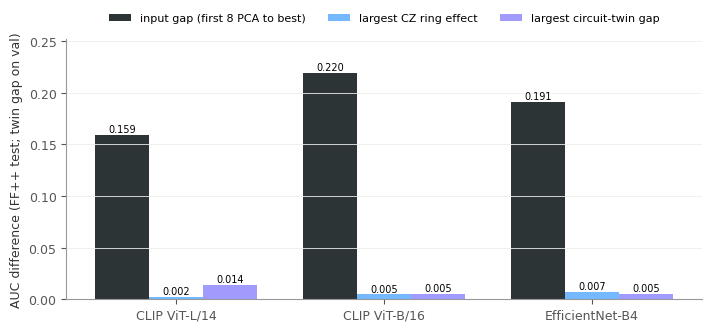

In [12]:
fig, ax = plt.subplots(figsize=(7.2, 3.4))
x = np.arange(len(backbones))
parts = [("input gap", "input gap (first 8 PCA to best)", "#2d3436"),
         ("CZ ring effect", "largest CZ ring effect", "#74b9ff"),
         ("circuit vs twin", "largest circuit-twin gap", "#a29bfe")]
for k, (key, label, color) in enumerate(parts):
    v = [c1[b][key] for b in backbones]
    bars = ax.bar(x + (k - 1) * 0.26, v, 0.26, color=color, label=label)
    for rect, value in zip(bars, v):
        ax.annotate(f"{value:.3f}", (rect.get_x() + rect.get_width() / 2, value), xytext=(0, 2),
                    textcoords="offset points", ha="center", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels([titles[b] for b in backbones])
ax.set_ylabel("AUC difference (FF++ test; twin gap on val)")
ax.set_ylim(0, max(c1[b]["input gap"] for b in backbones) * 1.15)
ax.legend(frameon=False, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3)
ax.grid(axis="y", color="#eeeeee", lw=0.6)
plt.tight_layout()
save_figure(fig, "f2_c1_gaps")

## 13. Figure 3: per manipulation on FF++ test

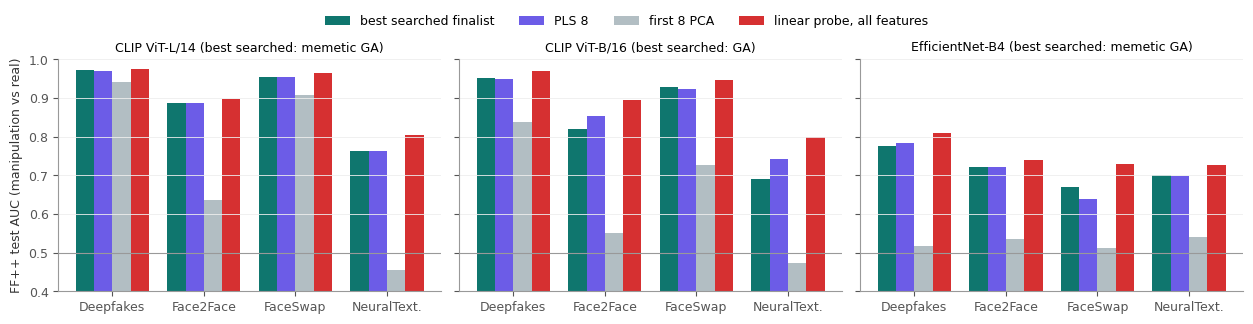

In [13]:
fig, axes = plt.subplots(1, len(backbones), figsize=(4.2 * len(backbones), 3.0), squeeze=False, sharey=True)
for ax, b in zip(axes[0], backbones):
    s = none.loc[b]
    best = s.loc[searched, "val"].idxmax()
    series = [("best searched finalist", s.loc[best], colors["best searched"]), ("PLS 8", s.loc["PLS 8"], colors["PLS 8"]),
              ("first 8 PCA", s.loc["first 8 PCA"], colors["first 8 PCA"]),
              ("linear probe, all features", probe.loc[b], colors["probe"])]
    xm = np.arange(len(manipulations))
    for k, (label, r, color) in enumerate(series):
        ax.bar(xm + (k - 1.5) * 0.2, [r[f"ffpp_test {m}"] for m in manipulations], 0.2, color=color, label=label)
    ax.axhline(0.5, color="#999999", lw=0.8)
    ax.set_xticks(xm)
    ax.set_xticklabels(["Deepfakes", "Face2Face", "FaceSwap", "NeuralText."])
    ax.set_ylim(0.4, 1.0)
    ax.set_title(f"{titles[b]} (best searched: {best})", fontsize=9)
    ax.grid(axis="y", color="#eeeeee", lw=0.6)
axes[0][0].set_ylabel("FF++ test AUC (manipulation vs real)")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.08))
plt.tight_layout()
save_figure(fig, "f3_per_manipulation")

## 14. Figure 4: share of the probe (C3)

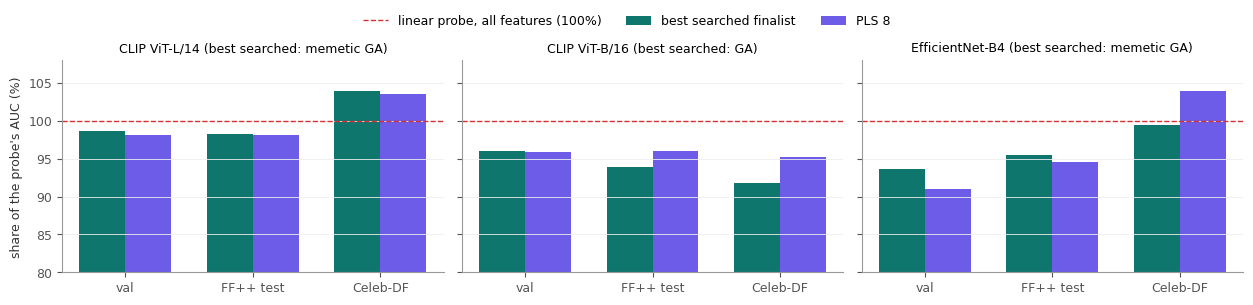

In [14]:
fig, axes = plt.subplots(1, len(backbones), figsize=(4.2 * len(backbones), 2.8), squeeze=False, sharey=True)
splits = ["val", "FF++ test", "Celeb-DF"]
for ax, b in zip(axes[0], backbones):
    xs = np.arange(len(splits))
    best_name = ""
    for k, (name, shares) in enumerate(c3[b].items()):
        if name == "PLS 8":
            color, label = colors["PLS 8"], "PLS 8"
        else:
            color, label = colors["best searched"], "best searched finalist"
            best_name = name.split("(")[1].rstrip(")")
        ax.bar(xs + (k - 0.5) * 0.36, [shares[s] * 100 for s in splits], 0.36, color=color, label=label)
    ax.axhline(100, color=colors["probe"], ls="--", lw=1, label="linear probe, all features (100%)")
    ax.set_xticks(xs)
    ax.set_xticklabels(splits)
    ax.set_ylim(80, 108)
    ax.set_title(f"{titles[b]} (best searched: {best_name})", fontsize=9)
    ax.grid(axis="y", color="#eeeeee", lw=0.6)
axes[0][0].set_ylabel("share of the probe's AUC (%)")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.09))
plt.tight_layout()
save_figure(fig, "f4_probe_share")

## 15. Figure 5: classical models on the same 8 inputs

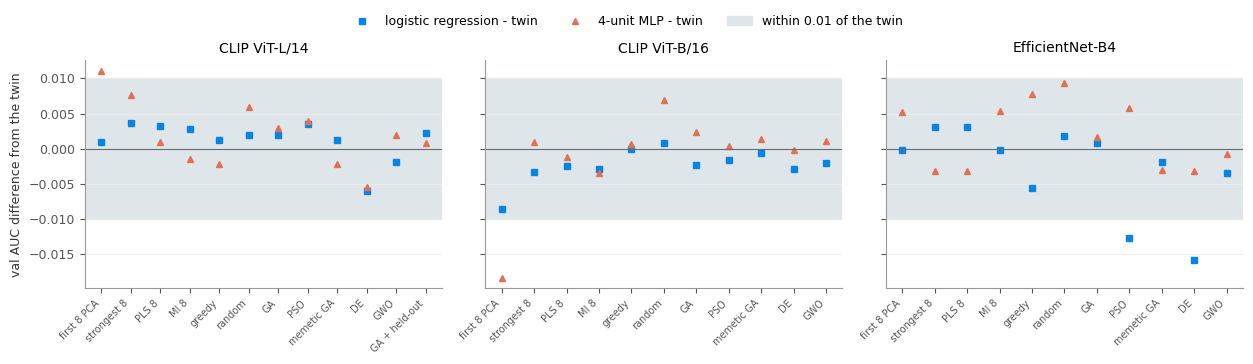

In [15]:
fig, axes = plt.subplots(1, len(backbones), figsize=(4.2 * len(backbones), 3.4), squeeze=False, sharey=True)
for ax, b in zip(axes[0], backbones):
    c = context[(context["backbone"] == b) & (context["model"] != "linear probe")]
    names = list(dict.fromkeys(c["row"]))
    for i, name in enumerate(names):
        g = c[c["row"] == name].set_index("model")
        ax.plot(i, g.loc["logistic regression", "val"] - g.loc["twin", "val"], "s", color="#0984e3", ms=4,
                label="logistic regression - twin" if i == 0 else None)
        ax.plot(i, g.loc["MLP", "val"] - g.loc["twin", "val"], "^", color="#e17055", ms=4,
                label="4-unit MLP - twin" if i == 0 else None)
    ax.axhspan(-0.01, 0.01, color="#dfe6e9", zorder=0)
    ax.axhline(0, color="#636e72", lw=0.8)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([n.replace(" top", "") for n in names], rotation=45, ha="right", fontsize=7)
    ax.set_title(titles[b], fontsize=10)
    ax.grid(axis="y", color="#eeeeee", lw=0.6)
axes[0][0].set_ylabel("val AUC difference from the twin")
handles, labels = axes[0][0].get_legend_handles_labels()
handles.append(matplotlib.patches.Patch(color="#dfe6e9", label="within 0.01 of the twin"))
fig.legend(handles, labels + ["within 0.01 of the twin"], loc="upper center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 1.07))
plt.tight_layout()
save_figure(fig, "f5_context")

## 16. Files

In [16]:
print(json.dumps({"tables": sorted(os.listdir(f"{out_dir}/tables")), "figures": sorted(os.listdir(f"{out_dir}/figures"))}, indent=1))

{
 "tables": [
  "t1_test.csv",
  "t1_test.md",
  "t1_test.tex",
  "t2_paired.csv",
  "t2_paired.md",
  "t2_paired.tex",
  "t3_entangler.csv",
  "t3_entangler.md",
  "t3_entangler.tex",
  "t4_c1.csv",
  "t4_c1.md",
  "t4_c1.tex",
  "t5_context.csv",
  "t5_context.md",
  "t5_context.tex",
  "t6_search_stats.csv",
  "t6_search_stats.md",
  "t6_search_stats.tex",
  "t7_c3.csv",
  "t7_c3.md",
  "t7_c3.tex"
 ],
 "figures": [
  "f1_test_auc.pdf",
  "f1_test_auc.png",
  "f2_c1_gaps.pdf",
  "f2_c1_gaps.png",
  "f3_per_manipulation.pdf",
  "f3_per_manipulation.png",
  "f4_probe_share.pdf",
  "f4_probe_share.png",
  "f5_context.pdf",
  "f5_context.png"
 ]
}
